# Session 2: Fitting an image with an MLP

In session 1 the MLP was small: two layers, a few hundred thousand operations per image.
Here we build a network that needs **depth**: an MLP that *is* an image.

It maps the coordinates of a pixel to its color,

$$
(x, y) \;\mapsto\; (r, g, b),
$$

and we train it on a single photo until it reproduces it. Rendering the image means running the
MLP on every pixel, so inference is a large batch of matmuls, which is exactly what `algeco` compiles.

Two ingredients make this work:

1. **Fourier features.** A ReLU MLP on raw $(x, y)$ learns smooth functions first and fine details
   very slowly ("spectral bias"). Mapping the coordinates to $[\sin(2\pi c B), \cos(2\pi c B)]$ with a
   random frequency matrix $B$ fixes this ([Tancik et al., 2020](https://arxiv.org/abs/2006.10739)).
2. **Depth and width.** A photo has a lot of detail. The network must be large enough to store it.

Training runs in PyTorch: this course is about inference, and training a network of this size is too slow
without a mature framework. The functions used here live in [`examples/image_mlp.py`](../examples/image_mlp.py).

In [5]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import threadpoolctl
import torch

sys.path.insert(0, "../examples")
import image_mlp as im

device = im.default_device()
print(f"torch {torch.__version__} on {device}, {torch.get_num_threads()} threads")
blas_threads = max(p["num_threads"] for p in threadpoolctl.threadpool_info())
if device.type == "cpu" and blas_threads == 1:
    print("Warning: BLAS is limited to 1 thread, training will be slow. Was Jupyter "
          "started from an old `pixi shell` with OMP_NUM_THREADS=1?")

torch 2.13.0 on cpu, 1 threads


## 1. The data

scikit-learn's sample image `china.jpg`, at half resolution to keep training fast.
Every pixel is one training sample: its center coordinates, scaled to $[0, 1]$, as input,
and its color as target.

image 320x214 = 68,480 pixels, coords (68480, 2), colors (68480, 3)


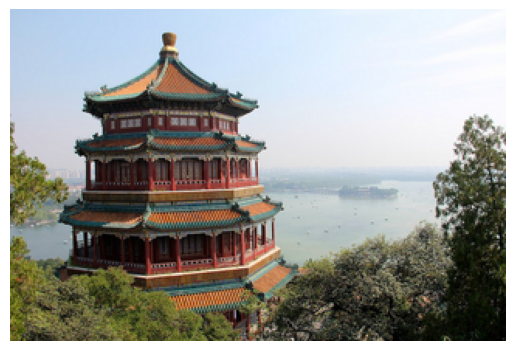

In [6]:
SCALE = 0.5
image = im.load_image(SCALE)
H, W, _ = image.shape
coords = im.pixel_coords(H, W)
print(f"image {W}x{H} = {H * W:,} pixels, coords {coords.shape}, colors {image.reshape(-1, 3).shape}")
plt.imshow(image)
plt.axis("off");

A helper that encodes the coordinates, trains a fresh network and reports the result.
The quality measure is the **PSNR** (peak signal-to-noise ratio) in dB. 20 dB is blurry,
30 dB looks good, and above 35 dB the result is hard to tell from the original.

Training cost grows with `width² · depth` and with `steps`. On a laptop CPU, the default
network (4×256) takes about a minute for 1000 steps. Results are cached in `runs`,
so re-running a cell only trains new configurations.

In [7]:
runs = {}

def fit(features=128, sigma=10.0, depth=4, width=256, steps=1000, seed=0):
    key = (features, sigma, depth, width, steps, seed)
    if key not in runs:
        torch.manual_seed(seed)
        B = im.random_frequencies(features, sigma, seed)
        x = im.fourier_features(coords, B)
        model = im.make_mlp(x.shape[1], width, depth)
        t0 = time.perf_counter()
        losses = im.train(model, x, image, steps=steps, device=device)
        seconds = time.perf_counter() - t0
        layers = im.export_weights(model)
        out = im.render(im.mlp_numpy(layers), x, (H, W))
        runs[key] = dict(
            B=B, layers=layers, losses=losses, image=out, seconds=seconds,
            psnr=im.psnr(out, image), params=sum(w.size + b.size for w, b in layers),
        )
        r = runs[key]
        print(f"F={features:4d} σ={sigma:5.1f} {depth}x{width:<4d}: "
              f"{r['psnr']:5.2f} dB, {r['params']:9,} params, {seconds:5.1f} s")
    return runs[key]

def show(results, titles, ncols=None):
    ncols = ncols or len(results)
    nrows = -(-len(results) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.9 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r, title in zip(axes.flat, results, titles):
        ax.imshow(r["image"] if isinstance(r, dict) else r)
        ax.set_title(title + (f"\n{r['psnr']:.1f} dB" if isinstance(r, dict) else ""), fontsize=9)
    plt.tight_layout()

## 2. Raw coordinates vs. Fourier features

The same network (4 hidden layers of 256 units), once on the raw coordinates and once on 128 random
Fourier features (256 inputs: a sine and a cosine each).

In [8]:
raw = fit(features=0)
ff = fit(features=128)
show([image, raw, ff], ["original", "raw (x, y)", "Fourier features"])

plt.figure(figsize=(6, 3))
for r, label in [(raw, "raw (x, y)"), (ff, "Fourier features")]:
    plt.semilogy(r["losses"], label=label)
plt.xlabel("step"); plt.ylabel("MSE"); plt.legend();

KeyboardInterrupt: 

## 3. The frequency scale σ

The entries of $B$ are drawn from $\mathcal{N}(0, \sigma^2)$, in periods per image side. σ sets the
finest detail the network can express: too small and the image is blurry, too large and the network
"hallucinates" high-frequency noise between pixels. (A smaller network keeps this sweep fast.)

In [ ]:
sigmas = [1, 5, 10, 25, 60]
results = [fit(sigma=s, depth=3, width=128) for s in sigmas]
show(results, [f"σ = {s}" for s in sigmas])

## 4. Depth and width

Now the network size. Each additional hidden layer adds a `width × width` matmul to the inference,
for every pixel. This is the cost that `algeco` has to make fast.

This sweep trains 12 networks. Expect a few minutes on a CPU; reduce `steps` or the lists to go faster.

In [ ]:
depths = [1, 2, 4, 6]
widths = [64, 128, 256]
STEPS = 500
grid = {(d, w): fit(depth=d, width=w, steps=STEPS) for d in depths for w in widths}

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
for w in widths:
    ax1.plot(depths, [grid[d, w]["psnr"] for d in depths], "o-", label=f"width {w}")
    ax2.semilogx([grid[d, w]["params"] for d in depths], [grid[d, w]["psnr"] for d in depths],
                 "o-", label=f"width {w}")
ax1.set_xlabel("hidden layers"); ax1.set_ylabel("PSNR [dB]"); ax1.legend()
ax2.set_xlabel("parameters"); ax2.set_ylabel("PSNR [dB]")
plt.tight_layout()

show([grid[d, w] for d in depths for w in widths],
     [f"{d} x {w}" for d in depths for w in widths], ncols=len(widths))

## 5. Your turn

Try to get the best PSNR you can within a training budget you can live with. Things to vary:

- `depth`, `width`: capacity (and inference cost)
- `features`, `sigma`: the input encoding
- `steps`: training time

Also try how far you can go *down*: what is the smallest network that still looks acceptable?
That is the network you would want to deploy on a small device.

In [ ]:
mine = fit(features=128, sigma=10, depth=6, width=256, steps=2000)
show([image, mine], ["original", "mine"])

## 6. Inference with algeco

The trained network runs in two stages:

1. the Fourier features, in NumPy (algeco has no `sin`/`cos`, and this stage is cheap),
2. the MLP, compiled by `algeco` with the trained weights as constants.

`algeco` compiles for fixed shapes, so `im.render` feeds the pixels in chunks of 4096 rows
and zero-pads the last chunk.

We use your network from section 5, or one of the models that `pixi run examples` trains once
and keeps in `examples/weights/` (see `examples/dodo.py`).

In [ ]:
B, layers = mine["B"], mine["layers"]
# B, layers, config = im.load_model(Path("../examples/weights/image_mlp-deep.npz"))

infer = im.mlp_algeco(layers)
x = im.fourier_features(coords, B)

t0 = time.perf_counter()
out = im.render(infer, x, (H, W))
print(f"compiled and rendered in {time.perf_counter() - t0:.1f} s")
np.testing.assert_allclose(out, im.render(im.mlp_numpy(layers), x, (H, W)), rtol=1e-3, atol=1e-3)
print(f"algeco matches NumPy, {len(layers) - 1} hidden layers, {im.psnr(out, image):.2f} dB")

The network has learned a continuous function, so it can be evaluated at any coordinate,
for example at full resolution, twice the resolution it was trained on.

That is 4× the pixels, too slow for the unoptimized loops `algeco` generates so far, so this cell
uses NumPy. Switch to `infer` once your passes make it fast.

In [ ]:
full = im.load_image(1.0)
x_full = im.fourier_features(im.pixel_coords(*full.shape[:2]), B)
out_full = im.render(im.mlp_numpy(layers), x_full, full.shape[:2])
show([full, out_full], ["original, full resolution", f"MLP, {im.psnr(out_full, full):.1f} dB"])

Finally the timing, single-threaded on both sides as in session 1. How does the gap to NumPy change
with the network size? Where does the time go: in the first layer (wide input), in the hidden
layers, or in the final layer with only 3 outputs?

In [ ]:
chunk = x[:4096]
with threadpoolctl.threadpool_limits(1):
    for name, f in [("algeco", infer), ("NumPy", im.mlp_numpy(layers))]:
        t = im.best_time(f, chunk, repeat=3) / len(chunk)
        print(f"{name:>7}: {t * 1e6:8.2f} µs per pixel, {t * H * W:6.2f} s per image")